
# Final Model Training and Held-Out Test Evaluation

This notebook implements the final evaluation of the RoBERTa classifier selected in `04_model_selection.ipynb` for identifying first-person sexual violence survivor narratives in Reddit posts.

The selected RoBERTa architecture (`roberta-base`) is fine-tuned using the complete annotated training dataset (n = 406), with the previously optimized hyperparameters. The resulting classifier is evaluated on the independent held-out test dataset (n = 174), which was excluded from model development, hyperparameter tuning, and decision threshold optimization.

A decision threshold of 0.32, established using five-fold out-of-fold predictions in Notebook 04, is applied without further modification. Model performance is assessed using accuracy, precision, sensitivity, specificity, F1-score, balanced accuracy, ROC-AUC, and average precision.

Finally, classification errors are examined to characterize potentially misclassified survivor narratives and assess implications for the construction of the dissertation's survivor-narrative corpus.


In [3]:

import json
import random
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import seaborn as sns

from datasets import Dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    DataCollatorWithPadding,
    Trainer,
    TrainingArguments
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    average_precision_score,
    roc_curve,
    precision_recall_curve
)

# Define project directories.
PROJECT_DIR = Path.cwd().parent
DATA_DIR = PROJECT_DIR / "data" / "processed"
RESULTS_DIR = Path.cwd() / "results"
MODEL_DIR = PROJECT_DIR / "models"

RESULTS_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)

# Set random seed for reproducibility.
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("Project directory:", PROJECT_DIR)
print("Results directory:", RESULTS_DIR)
print("Model directory:", MODEL_DIR)
print("PyTorch version:", torch.__version__)
print("MPS available:", torch.backends.mps.is_available())
print("CUDA available:", torch.cuda.is_available())


Project directory: /Users/Kashif/Library/CloudStorage/Box-Box/0.KB_NLP
Results directory: /Users/Kashif/Library/CloudStorage/Box-Box/0.KB_NLP/notebooks/results
Model directory: /Users/Kashif/Library/CloudStorage/Box-Box/0.KB_NLP/models
PyTorch version: 2.14.1
MPS available: True
CUDA available: False


In [7]:
CONFIG_PATH = (
    PROJECT_DIR
    / "models"
    / "survivor_narrative_roberta"
    / "survivor_narrative_roberta_config.json"
)


print("Configuration path:", CONFIG_PATH)
print("Configuration file exists:", CONFIG_PATH.exists())


Configuration path: /Users/Kashif/Library/CloudStorage/Box-Box/0.KB_NLP/models/survivor_narrative_roberta/survivor_narrative_roberta_config.json
Configuration file exists: True


In [8]:

# Load the selected model configuration.
with open(CONFIG_PATH, "r", encoding="utf-8") as f:
    selected_config = json.load(f)

# Display the complete configuration.
print(json.dumps(selected_config, indent=4))


{
    "model_name": "RoBERTa",
    "pretrained_model": "roberta-base",
    "decision_threshold": 0.32,
    "hyperparameters": {
        "learning_rate": 1e-05,
        "num_train_epochs": 3,
        "per_device_train_batch_size": 2,
        "weight_decay": 0.01,
        "max_length": 512,
        "random_state": 42
    },
    "selection_criteria": {
        "primary_metric": "sensitivity",
        "minimum_sensitivity": 0.95,
        "secondary_metric": "specificity",
        "selection_data": "5-fold out-of-fold training predictions"
    },
    "training_sample_size": 406,
    "held_out_test_size": 174
}


In [9]:

# Extract selected model specifications.
MODEL_NAME = selected_config["pretrained_model"]
SELECTED_THRESHOLD = selected_config["decision_threshold"]

# Extract selected hyperparameters.
hyperparams = selected_config["hyperparameters"]

LEARNING_RATE = hyperparams["learning_rate"]
NUM_EPOCHS = hyperparams["num_train_epochs"]
BATCH_SIZE = hyperparams["per_device_train_batch_size"]
WEIGHT_DECAY = hyperparams["weight_decay"]
MAX_LENGTH = hyperparams["max_length"]
SEED = hyperparams["random_state"]

print("Model:", MODEL_NAME)
print("Threshold:", SELECTED_THRESHOLD)
print("Hyperparameters loaded successfully.")


Model: roberta-base
Threshold: 0.32
Hyperparameters loaded successfully.



## Loading and Validating the Datasets

The annotated dataset was previously partitioned into stratified training (70%) and test (30%) subsets. The training subset was used for model development, cross-validation, hyperparameter optimization, and decision threshold selection.

The held-out test subset was excluded from all preceding model development procedures.

Both datasets are loaded and validated to confirm their expected sample sizes, binary outcome labels, and class distributions. Post titles and self-text are combined to construct the textual input for RoBERTa, consistent with the preceding notebooks.


In [10]:

# Load training and held-out test datasets.
train_df = pd.read_csv(DATA_DIR / "narr_train_70.csv")
test_df = pd.read_csv(DATA_DIR / "narr_test_30.csv")

# Validate sample sizes.
assert len(train_df) == 406, "Unexpected training sample size."
assert len(test_df) == 174, "Unexpected test sample size."

# Validate required columns.
required_columns = ["title", "selftext", "survivor_narrative"]

for name, df in [("Training", train_df), ("Test", test_df)]:
    assert all(col in df.columns for col in required_columns), (
        f"{name} dataset is missing required columns."
    )

    assert df["survivor_narrative"].notna().all(), (
        f"{name} dataset contains missing outcome labels."
    )

    assert df["survivor_narrative"].isin([0, 1]).all(), (
        f"{name} dataset contains invalid outcome labels."
    )

# Construct text inputs.
X_train = (
    train_df["title"].fillna("") + " " +
    train_df["selftext"].fillna("")
).str.strip()

X_test = (
    test_df["title"].fillna("") + " " +
    test_df["selftext"].fillna("")
).str.strip()

# Extract outcome labels.
y_train = train_df["survivor_narrative"].astype(int)
y_test = test_df["survivor_narrative"].astype(int)

# Check for empty text.
assert X_train.ne("").all(), "Empty training text detected."
assert X_test.ne("").all(), "Empty test text detected."

# Display dataset characteristics.
print("Training observations:", len(X_train))
print("Test observations:", len(X_test))
print("Total observations:", len(X_train) + len(X_test))

print("\nTraining class distribution:")
print(y_train.value_counts().sort_index())

print("\nTest class distribution:")
print(y_test.value_counts().sort_index())

print("\nDataset validation completed successfully.")


Training observations: 406
Test observations: 174
Total observations: 580

Training class distribution:
survivor_narrative
0    100
1    306
Name: count, dtype: int64

Test class distribution:
survivor_narrative
0     43
1    131
Name: count, dtype: int64

Dataset validation completed successfully.



## Tokenization and Dataset Preparation

Following the tokenization procedures established in Notebooks 03 and 04, the training and held-out test datasets were prepared using the pretrained RoBERTa tokenizer (`roberta-base`), with truncation at 512 tokens and dynamic batch padding.

No additional tokenization parameters were optimized. The previously established preprocessing strategy was applied consistently to support final model training and independent evaluation.


In [11]:

# Initialize the selected tokenizer.
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

# Construct Hugging Face datasets.
train_dataset = Dataset.from_dict({
    "text": X_train.tolist(),
    "labels": y_train.tolist()
})

test_dataset = Dataset.from_dict({
    "text": X_test.tolist(),
    "labels": y_test.tolist()
})

# Define tokenization function.
def tokenize_function(batch):
    return tokenizer(
        batch["text"],
        truncation=True,
        max_length=MAX_LENGTH
    )

# Tokenize both datasets.
train_tokenized = train_dataset.map(
    tokenize_function,
    batched=True,
    remove_columns=["text"]
)

test_tokenized = test_dataset.map(
    tokenize_function,
    batched=True,
    remove_columns=["text"]
)

# Initialize dynamic padding.
data_collator = DataCollatorWithPadding(
    tokenizer=tokenizer
)

# Verify tokenized datasets.
print("Tokenizer:", tokenizer.name_or_path)
print("Maximum sequence length:", MAX_LENGTH)
print("Training observations:", len(train_tokenized))
print("Test observations:", len(test_tokenized))

print("\nTokenized dataset features:")
print(train_tokenized.features)

print("\nTokenization completed successfully.")


Map:   0%|          | 0/406 [00:00<?, ? examples/s]

Map:   0%|          | 0/174 [00:00<?, ? examples/s]

Tokenizer: roberta-base
Maximum sequence length: 512
Training observations: 406
Test observations: 174

Tokenized dataset features:
{'labels': Value('int64'), 'input_ids': List(Value('int32')), 'attention_mask': List(Value('int8'))}

Tokenization completed successfully.



## Final RoBERTa Model Training

The selected RoBERTa classifier was fine-tuned on the complete training dataset (n = 406) using the hyperparameters established through five-fold cross-validation and model selection.

The final training procedure used a learning rate of 1e-5, batch size of 2, weight decay of 0.01, and three training epochs. A random seed of 42 was maintained for reproducibility.

No validation or test observations were used for further model selection. The resulting model and tokenizer were saved for independent evaluation and subsequent application to the unannotated Reddit corpus.


In [12]:

import gc

# Release previously loaded models, if present.
if "trainer" in globals():
    del trainer
if "model" in globals():
    del model

gc.collect()

if torch.backends.mps.is_available():
    torch.mps.empty_cache()

# Set random seeds.
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# Initialize the final RoBERTa classifier.
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=2
)

# Configure final training.
training_args = TrainingArguments(
    output_dir=str(RESULTS_DIR / "roberta_final"),
    learning_rate=LEARNING_RATE,
    per_device_train_batch_size=BATCH_SIZE,
    per_device_eval_batch_size=BATCH_SIZE,
    num_train_epochs=NUM_EPOCHS,
    weight_decay=WEIGHT_DECAY,
    save_strategy="no",
    logging_strategy="epoch",
    report_to="none",
    seed=SEED,
    data_seed=SEED
)

# Initialize trainer using the complete training dataset.
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_tokenized,
    data_collator=data_collator
)

print("Training device:", training_args.device)
print("Training observations:", len(train_tokenized))
print("Learning rate:", LEARNING_RATE)
print("Epochs:", NUM_EPOCHS)
print("Batch size:", BATCH_SIZE)

# Fine-tune the final model.
train_result = trainer.train()

# Save the final model and tokenizer.
FINAL_MODEL_DIR = MODEL_DIR / "survivor_narrative_roberta" / "final_model"
FINAL_MODEL_DIR.mkdir(parents=True, exist_ok=True)

trainer.save_model(str(FINAL_MODEL_DIR))
tokenizer.save_pretrained(str(FINAL_MODEL_DIR))

print("\nFinal model training completed.")
print("Training loss:", train_result.training_loss)
print("Model saved to:", FINAL_MODEL_DIR)


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: roberta-base
Key                        | Status     | 
---------------------------+------------+-
lm_head.dense.bias         | UNEXPECTED | 
lm_head.bias               | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.layer_norm.bias    | UNEXPECTED | 
classifier.dense.bias      | MISSING    | 
classifier.out_proj.weight | MISSING    | 
classifier.out_proj.bias   | MISSING    | 
classifier.dense.weight    | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Training device: mps
Training observations: 406
Learning rate: 1e-05
Epochs: 3
Batch size: 2


/opt/anaconda3/lib/python3.13/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


Step,Training Loss
203,0.644345
406,0.295670
609,0.212936


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


Final model training completed.
Training loss: 0.3843171819677494
Model saved to: /Users/Kashif/Library/CloudStorage/Box-Box/0.KB_NLP/models/survivor_narrative_roberta/final_model



## Independent Held-Out Test Evaluation

The final RoBERTa classifier was evaluated on the independent held-out test dataset (n = 174), which was excluded from model training, cross-validation, hyperparameter optimization, and decision threshold selection.

Predicted probabilities for the survivor-narrative class were obtained using the softmax transformation of the model's output logits. Binary classifications were generated using the predetermined decision threshold of 0.32.

Performance was assessed using accuracy, precision, sensitivity, specificity, balanced accuracy, F1-score, ROC-AUC, and average precision (area under the precision-recall curve). Sensitivity was prioritized because false-negative classifications could result in the exclusion of relevant survivor narratives from the dissertation corpus.


In [13]:

# Generate predictions on the held-out test dataset.
test_output = trainer.predict(test_tokenized)

# Convert logits into class probabilities.
test_probabilities = torch.softmax(
    torch.tensor(test_output.predictions),
    dim=1
).numpy()[:, 1]

# Apply the previously selected decision threshold.
test_predictions = (
    test_probabilities >= SELECTED_THRESHOLD
).astype(int)

# Calculate confusion matrix components.
tn, fp, fn, tp = confusion_matrix(
    y_test,
    test_predictions,
    labels=[0, 1]
).ravel()

# Calculate evaluation metrics.
test_metrics = {
    "accuracy": accuracy_score(y_test, test_predictions),
    "precision": precision_score(
        y_test, test_predictions, zero_division=0
    ),
    "sensitivity": recall_score(
        y_test, test_predictions, zero_division=0
    ),
    "specificity": tn / (tn + fp),
    "balanced_accuracy": balanced_accuracy_score(
        y_test, test_predictions
    ),
    "f1": f1_score(
        y_test, test_predictions, zero_division=0
    ),
    "roc_auc": roc_auc_score(
        y_test, test_probabilities
    ),
    "average_precision": average_precision_score(
        y_test, test_probabilities
    )
}

# Display results.
print("FINAL HELD-OUT TEST PERFORMANCE")
print("-" * 40)

for metric, value in test_metrics.items():
    print(f"{metric:20s}: {value:.3f}")

print("\nCONFUSION MATRIX COMPONENTS")
print("-" * 40)
print("True negatives:", tn)
print("False positives:", fp)
print("False negatives:", fn)
print("True positives:", tp)


/opt/anaconda3/lib/python3.13/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


FINAL HELD-OUT TEST PERFORMANCE
----------------------------------------
accuracy            : 0.925
precision           : 0.947
sensitivity         : 0.954
specificity         : 0.837
balanced_accuracy   : 0.896
f1                  : 0.951
roc_auc             : 0.962
average_precision   : 0.986

CONFUSION MATRIX COMPONENTS
----------------------------------------
True negatives: 36
False positives: 7
False negatives: 6
True positives: 125



## Visualization of Held-Out Test Performance

Classification performance was visualized using a confusion matrix, receiver operating characteristic (ROC) curve, and precision-recall curve.

The confusion matrix summarizes correctly and incorrectly classified observations using the predetermined decision threshold of 0.32. The ROC and precision-recall curves characterize model discrimination across possible classification thresholds.

These visualizations provide complementary assessments of performance, particularly given the imbalance between survivor narratives and non-narratives.


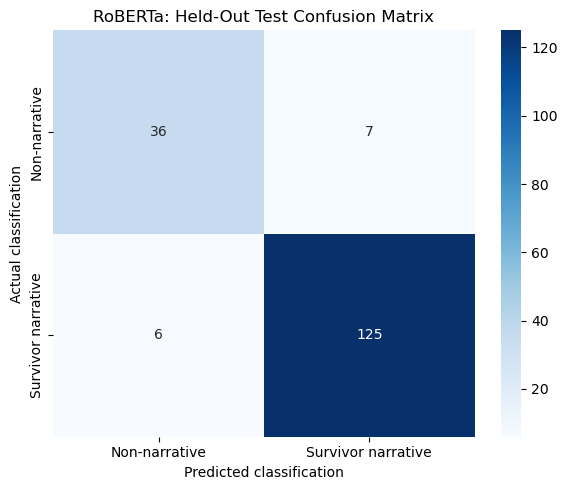

Confusion matrix saved to: /Users/Kashif/Library/CloudStorage/Box-Box/0.KB_NLP/outputs/figures


In [17]:

# Define figure output directory.
FIGURE_DIR = PROJECT_DIR / "outputs" / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

# Create confusion matrix.
cm = confusion_matrix(
    y_test,
    test_predictions,
    labels=[0, 1]
)

fig, ax = plt.subplots(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Non-narrative", "Survivor narrative"],
    yticklabels=["Non-narrative", "Survivor narrative"],
    ax=ax
)

ax.set_xlabel("Predicted classification")
ax.set_ylabel("Actual classification")
ax.set_title("RoBERTa: Held-Out Test Confusion Matrix")

plt.tight_layout()

# Save high-resolution PNG.
fig.savefig(
    FIGURE_DIR / "final_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

# Save vector PDF for publications.
fig.savefig(
    FIGURE_DIR / "final_confusion_matrix.pdf",
    bbox_inches="tight"
)

# Display figure.
plt.show()

print("Confusion matrix saved to:", FIGURE_DIR)


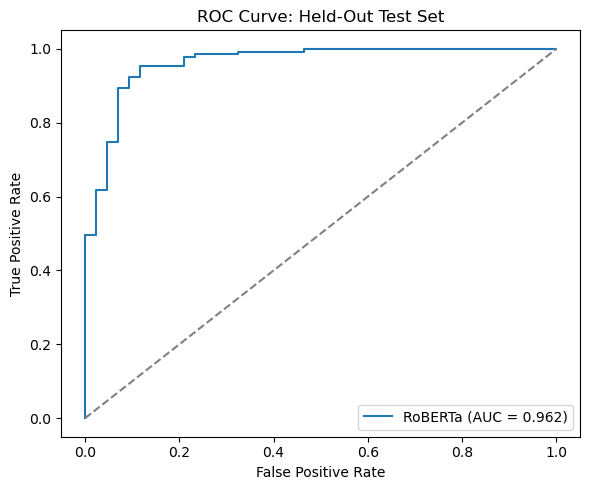

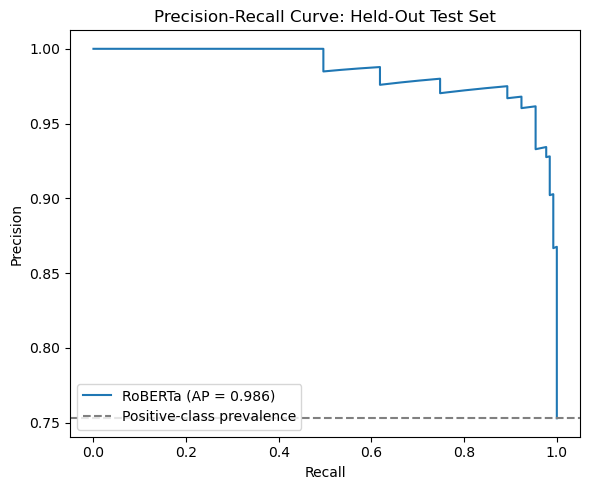

All evaluation figures saved to: /Users/Kashif/Library/CloudStorage/Box-Box/0.KB_NLP/outputs/figures


In [18]:

# Calculate ROC curve.
fpr, tpr, _ = roc_curve(
    y_test,
    test_probabilities
)

fig, ax = plt.subplots(figsize=(6, 5))

ax.plot(
    fpr,
    tpr,
    label=f"RoBERTa (AUC = {test_metrics['roc_auc']:.3f})"
)

ax.plot(
    [0, 1], [0, 1],
    linestyle="--",
    color="gray"
)

ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_title("ROC Curve: Held-Out Test Set")
ax.legend(loc="lower right")

plt.tight_layout()

fig.savefig(
    FIGURE_DIR / "final_roc_curve.png",
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    FIGURE_DIR / "final_roc_curve.pdf",
    bbox_inches="tight"
)

plt.show()


# Calculate precision-recall curve.
precision, recall, _ = precision_recall_curve(
    y_test,
    test_probabilities
)

fig, ax = plt.subplots(figsize=(6, 5))

ax.plot(
    recall,
    precision,
    label=f"RoBERTa (AP = {test_metrics['average_precision']:.3f})"
)

ax.axhline(
    y=y_test.mean(),
    linestyle="--",
    color="gray",
    label="Positive-class prevalence"
)

ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title("Precision-Recall Curve: Held-Out Test Set")
ax.legend(loc="lower left")

plt.tight_layout()

fig.savefig(
    FIGURE_DIR / "final_precision_recall_curve.png",
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    FIGURE_DIR / "final_precision_recall_curve.pdf",
    bbox_inches="tight"
)

plt.show()

print("All evaluation figures saved to:", FIGURE_DIR)



## Classification Error Analysis

An exploratory error analysis was conducted to characterize misclassifications in the independent held-out test dataset. False negatives and false positives were identified by comparing the model's binary predictions against manually annotated reference labels.

Particular attention was given to false negatives because these represent survivor narratives that would be excluded from the downstream dissertation corpus. Misclassified observations were examined descriptively to identify potential sources of classification difficulty, including indirect disclosures, ambiguous language, narrative structure, and contextual information.

This analysis was conducted after final model evaluation and was not used to modify the classifier, hyperparameters, or decision threshold.


In [19]:

# Create a dataframe of held-out test predictions.
test_results = test_df.copy()

test_results["predicted_probability"] = test_probabilities
test_results["predicted_label"] = test_predictions

# Identify classification outcomes.
test_results["classification"] = np.select(
    [
        (y_test == 1) & (test_predictions == 1),
        (y_test == 0) & (test_predictions == 0),
        (y_test == 0) & (test_predictions == 1),
        (y_test == 1) & (test_predictions == 0)
    ],
    [
        "True Positive",
        "True Negative",
        "False Positive",
        "False Negative"
    ],
    default="Unknown"
)

# Extract misclassified observations.
false_negatives = test_results[
    test_results["classification"] == "False Negative"
].copy()

false_positives = test_results[
    test_results["classification"] == "False Positive"
].copy()

# Display summary.
print("False negatives:", len(false_negatives))
print("False positives:", len(false_positives))
print("Total misclassifications:", len(false_negatives) + len(false_positives))

# Display post titles and predicted probabilities.
print("\nFALSE NEGATIVES")
display(
    false_negatives[
        ["title", "predicted_probability"]
    ].sort_values("predicted_probability")
)

print("\nFALSE POSITIVES")
display(
    false_positives[
        ["title", "predicted_probability"]
    ].sort_values("predicted_probability", ascending=False)
)


False negatives: 6
False positives: 7
Total misclassifications: 13

FALSE NEGATIVES


,title,predicted_probability
100,The truth.,0.001582
147,Was this coercion?,0.002265
152,How did that experience change you as a person?,0.006341
36,Was raped by my cousin and sister,0.012359
75,An interesting twist in my rape case,0.017685
28,It shouldn't matter,0.022487



FALSE POSITIVES


,title,predicted_probability
89,Am I not the only one who wish to get raped?,0.999516
115,Dissociation From Past,0.999458
2,What did I do to deserve this?,0.999342
120,Once upon a time,0.998312
127,HELPP HELPP BIG WOMEN RAPING ME,0.994802
165,How long was it after the abuse occurred befor...,0.858050
61,How do I support my boyfriend?,0.822086



## Saving Final Evaluation Results

The final held-out test predictions and classification performance metrics were saved to preserve the results of the independent evaluation.

These outputs document the performance of the selected RoBERTa classifier at the predetermined decision threshold of 0.32 and support reproducibility, reporting, and subsequent corpus classification.


In [21]:

# Define final output directories.
OUTPUT_DIR = PROJECT_DIR / "outputs"
TABLE_DIR = OUTPUT_DIR / "tables"

TABLE_DIR.mkdir(parents=True, exist_ok=True)

# Save final test predictions.
test_results.to_csv(
    TABLE_DIR / "final_test_predictions.csv",
    index=False
)

# Save final evaluation metrics.
metrics_output = {
    "model": MODEL_NAME,
    "decision_threshold": SELECTED_THRESHOLD,
    "training_sample_size": len(train_df),
    "test_sample_size": len(test_df),
    "metrics": test_metrics,
    "confusion_matrix": {
        "true_negatives": int(tn),
        "false_positives": int(fp),
        "false_negatives": int(fn),
        "true_positives": int(tp)
    }
}

with open(
    TABLE_DIR / "final_test_metrics.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(metrics_output, f, indent=4)

print("Final predictions and metrics saved successfully.")
print("Output directory:", TABLE_DIR)


Final predictions and metrics saved successfully.
Output directory: /Users/Kashif/Library/CloudStorage/Box-Box/0.KB_NLP/outputs/tables



## Summary and Conclusions

The final RoBERTa classifier demonstrated strong performance in identifying first-person sexual violence survivor narratives within the independent held-out test dataset (n = 174).

At the predetermined classification threshold of 0.32, the model achieved an accuracy of 92.5%, sensitivity of 95.4%, specificity of 83.7%, precision of 94.7%, and F1-score of 0.951. Discrimination was also strong, with an ROC-AUC of 0.962 and average precision of 0.986.

Of the 131 annotated survivor narratives, 125 were correctly identified, while six were incorrectly classified as non-narratives. Among the 43 annotated non-narratives, 36 were correctly excluded and seven were incorrectly classified as survivor narratives.

The classifier met the prespecified sensitivity target of at least 95%, while maintaining substantially better specificity than the initial logistic regression baseline.

### Limitations

Several limitations warrant consideration. First, the held-out test sample was relatively small, and performance estimates may vary across additional samples. Second, the annotated dataset contained a greater proportion of survivor narratives than non-narratives, potentially limiting generalizability to datasets with different class distributions.

Third, the 512-token maximum input length may have excluded relevant contextual information from longer Reddit posts. Finally, classification errors indicate that some survivor narratives may be excluded and some non-narratives retained when the model is applied to previously unseen data.

### Next Steps

The finalized RoBERTa classifier will be applied to the cleaned corpus of 2,960 English-language Reddit posts to identify observations suitable for subsequent dissertation analyses.

This classification procedure represents a preliminary corpus-development stage rather than the final analysis of hegemonic masculinity or help-seeking constructs. Those constructs will be examined in subsequent dissertation research.
